In [31]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [32]:
golf = pd.read_csv("time_series_US_20031231-1800_20261013-2329.csv")
golf = golf[:-8]
N = len(golf)
y = golf['golf']
t = np.arange(1, N+1)

y = golf['golf']

X = np.zeros((N,N+2))

for i in range(1,N):
    X[:,i] = np.maximum((t - i),0)
X[:,0] = 1

X[:,N] = np.cos(2*np.pi*t*(1/12))
X[:,N+1] = np.sin(2*np.pi*t*(1/12))

sym.pprint(X)
golf.head(-5)


[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00 ...  0.00000000e+00
                    8.66025404e-01  5.00000000e-01]                  
 [ 1.00000000e+00  1.00000000e+00  0.00000000e+00 ...  0.00000000e+00
                    5.00000000e-01  8.66025404e-01]                  
 [ 1.00000000e+00  2.00000000e+00  1.00000000e+00 ...  0.00000000e+00
                    6.12323400e-17  1.00000000e+00]                  
                                 ...                                 
 [ 1.00000000e+00  2.63000000e+02  2.62000000e+02 ...  0.00000000e+00
                    1.00000000e+00 -1.95993006e-14]                  
 [ 1.00000000e+00  2.64000000e+02  2.63000000e+02 ...  0.00000000e+00
                    8.66025404e-01  5.00000000e-01]                  
 [ 1.00000000e+00  2.65000000e+02  2.64000000e+02 ...  1.00000000e+00
                    5.00000000e-01  8.66025404e-01]]                 


,Time,golf
0,2004-01-01,45
1,2004-02-01,50
2,2004-03-01,62
3,2004-04-01,77
4,2004-05-01,79
...,...,...
256,2025-05-01,67
257,2025-06-01,79
258,2025-07-01,76
259,2025-08-01,66


In [33]:
K = 5
idx = np.arange(N)

D = np.ones(N+2)
D[:2] = 0
D = np.diag(D)

lmbda = np.logspace(0,6,7)


cv_error = []
for lam in lmbda:
    fold_error = []
    for k in range(K):
        test  = (idx % K == k)
        train = ~test
        X_train, y_train = X[train], y[train]
        X_test,  y_test  = X[test],  y[test]

        A = X_train.T @ X_train + lam * D
        b = X_train.T @ y_train
        beta_hat = np.linalg.solve(A, b)

        pred = X_test @ beta_hat
        fold_error.append(np.mean((y_test - pred)**2))

    cv_error.append(np.mean(fold_error))   # one number per λ

best_lam = lmbda[np.argmin(cv_error)]
print(best_lam)

1.0


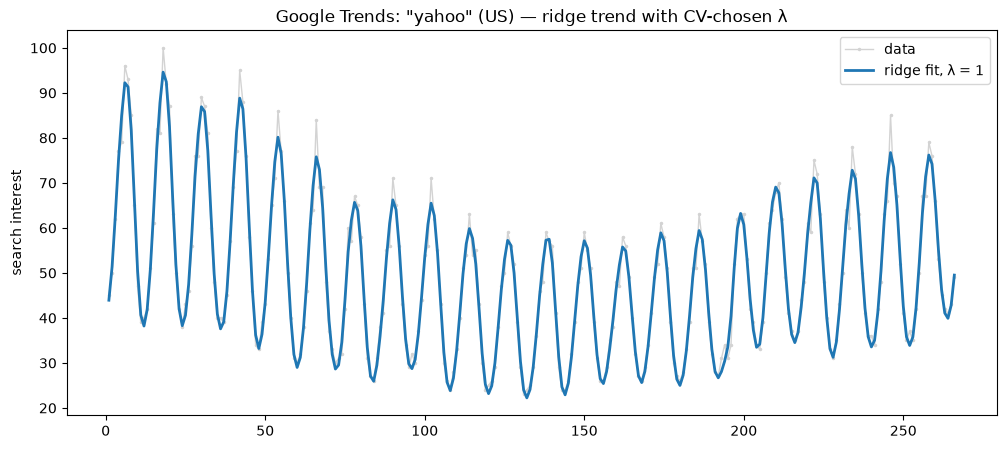

In [34]:
A = X.T @ X + best_lam * D
beta_best = np.linalg.solve(A, X.T @ y)
mu_best = X @ beta_best

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, marker='.', ms=3, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge fit, λ = {best_lam:.3g}')
plt.ylabel('search interest'); plt.title('Google Trends: "yahoo" (US) — ridge trend with CV-chosen λ')
plt.legend()
plt.show()

The model does a good job capturing the general trend but it struggle sto capture the full peaks of each period. However compared to the model from question 5 this model is able to capture the troughs.

Part B

i

In [35]:
n = len(y)
XtX = X.T @ X
Xty = X.T @ y
yty = y @ y

def log_post(tau,sigma):
    M = XtX/sigma**2 + D/tau**2
    _, logdet = np.linalg.slogdet(M)
    quad =( Xty.T @ np.linalg.inv(M) @ Xty ) / sigma**4 
    return -(n-2)*np.log(tau) - n*np.log(sigma) - .5 *logdet - .5*(yty/sigma**2 - quad)

sig0 = np.std(y - mu_best)
tau0 = sig0 / np.sqrt(best_lam)
taus   = tau0 * np.logspace(-2, 2, 60)
sigmas = sig0 * np.logspace(-1, 1, 60)

LP = np.array([[log_post(ta,si) for si in sigmas] for ta in taus])

i, j = np.unravel_index(np.argmax(LP), LP.shape)
tau_hat, sigma_hat = taus[i], sigmas[j]
print(f"tau_hat = {tau_hat:.4g}, sigma_hat = {sigma_hat:.4g}")
print(f"sigma^2/tau^2 = {sigma_hat**2 / tau_hat**2:.4g}   vs   CV lambda = {best_lam:.4g}")


tau_hat = 243.6, sigma_hat = 0.3329
sigma^2/tau^2 = 1.867e-06   vs   CV lambda = 1


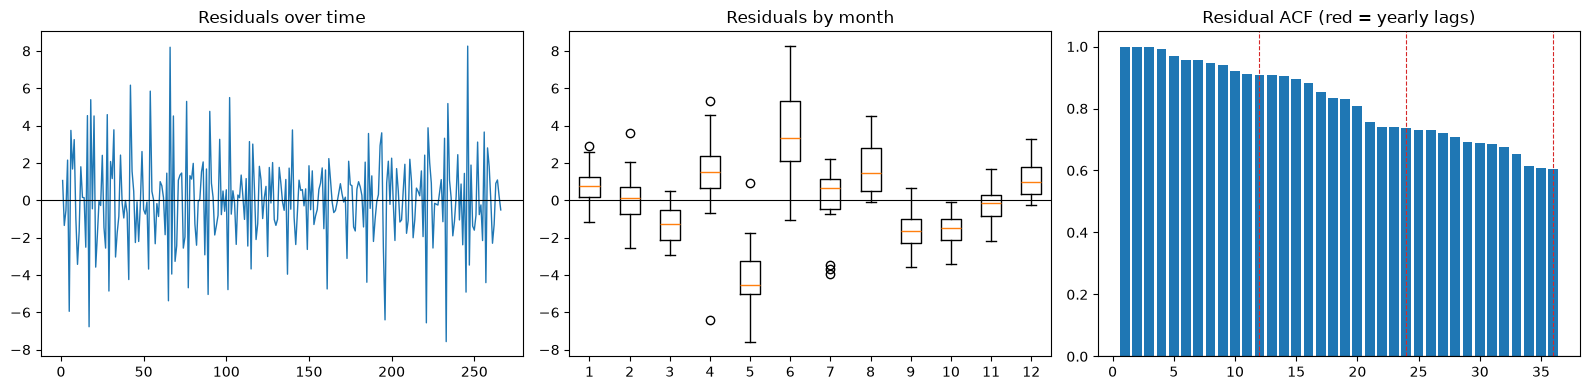

In [36]:
fit_full = X @ beta_best          
resid = y - fit_full
month = (np.arange(n) % 12) + 1   

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. residuals over time
axes[0].plot(t, resid, lw=1)
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_title('Residuals over time')

# 2. residuals by calendar month
axes[1].boxplot([resid[month == m] for m in range(1, 13)], label=list('JFMAMJJASOND'))
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('Residuals by month')

# 3. autocorrelation of residuals
lags = np.arange(1, 37)
r = resid - resid.mean()
acf = [np.sum(r[:-k] * r[k:]) / np.sum(r**2) for k in lags]
axes[2].bar(lags, acf)
axes[2].axhline(0, color='k', lw=0.8)
for k in (12, 24, 36):
    axes[2].axvline(k, color='C3', ls='--', lw=0.8)
axes[2].set_title('Residual ACF (red = yearly lags)')

fig.tight_layout()
plt.show()

ii

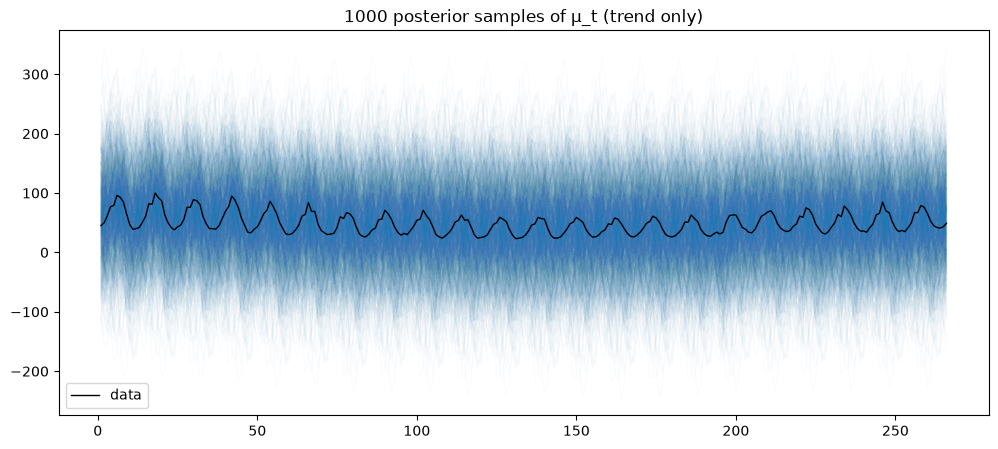

In [37]:
from scipy.linalg import cho_factor, cho_solve, solve_triangular

p = N + 2                     
Xty = X.T @ y

rng = np.random.default_rng(0)
Nsamp = 1000


P = np.exp(LP - LP.max())
P /= P.sum()
flat = rng.choice(P.size, size=Nsamp, p=P.ravel())
ti, si = np.unravel_index(flat, P.shape)


mu_condmean = np.empty((Nsamp,N))
mu_samples  = np.empty((Nsamp, N))
seas_samples = np.empty((Nsamp, N))
for s in range(Nsamp):
    mu_condmean[s] = X[:, :N] @ mean[:N]
    tau, sigma = taus[ti[s]], sigmas[si[s]]
    M = XtX / sigma**2 + D / tau**2
    c, low = cho_factor(M, lower=True)
    mean = cho_solve((c, low), Xty / sigma**2)
    z = rng.standard_normal(p)
    beta = mean + solve_triangular(c, z, lower=True, trans='T')
    mu_samples[s]   = X[:, :N] @ beta[:N]      
    seas_samples[s] = X[:, N:] @ beta[N:]     


plt.figure(figsize=(12, 5))
plt.plot(t, y, color='black', lw=1, label='data', zorder=3)
for s in range(Nsamp):
    plt.plot(t, mu_samples[s], color='C0', alpha=0.02, lw=1)
plt.title('1000 posterior samples of μ_t (trend only)')
plt.legend()
plt.show()


The posterer seeems to ahve a lot of uncertainty as we can see all the posterie samples very scatter around the actual data. This to me implies that we cannot fully trust or call this model a fit for the data similarly the errors seem to be or the uncertainty seems to be quite high.

iii

roughness  ridge (a):          631.8
roughness  Bayes (cond. means): 1.955e+04
roughness  Bayes (raw samples): 1.971e+04


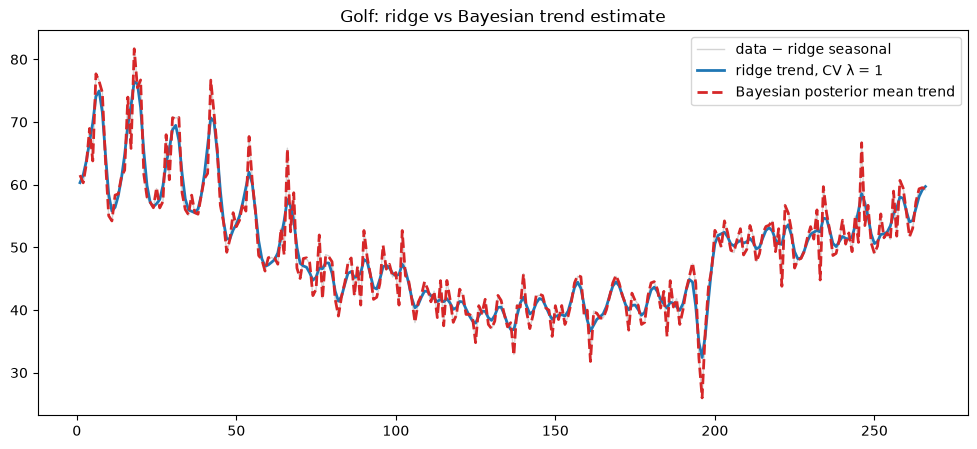

In [38]:

mu_bayes_raw = mu_samples.mean(axis=0)     
mu_bayes     = mu_condmean.mean(axis=0)  


mu_ridge = X[:, :N] @ beta_best[:N]


rough = lambda m: np.sum(np.diff(m, 2)**2)
print(f"roughness  ridge (a):          {rough(mu_ridge):.4g}")
print(f"roughness  Bayes (cond. means): {rough(mu_bayes):.4g}")
print(f"roughness  Bayes (raw samples): {rough(mu_bayes_raw):.4g}")


seas_ridge = X[:, N:] @ beta_best[N:]
plt.figure(figsize=(12, 5))
plt.plot(t, y - seas_ridge, color='lightgray', lw=1, label='data − ridge seasonal')
plt.plot(t, mu_ridge, color='C0', lw=2, label=f'ridge trend, CV λ = {best_lam:.3g}')
plt.plot(t, mu_bayes, color='C3', lw=2, ls='--', label='Bayesian posterior mean trend')
plt.title('Golf: ridge vs Bayesian trend estimate')
plt.legend(); plt.show()